# Lab 21: Prediction and Posterior Predictive Checks

This lab asks two of Chapter 21's questions of the reference Bayesian MMM from Lab 15.
First, can the model predict weeks it has not seen?
It is fitted to the first two and a half years and asked to predict the last half year, and the check is whether its 90 per cent intervals contain about 90 per cent of the held-out weeks.
Second, can the model fitted to every week regenerate data that look like the observed Sedge Shoes revenue, week by week and in summary statistics such as the biggest week?
It accompanies Chapter 21 of the book Marketing Mix Modelling.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pymc as pm

from mmm_book import RANDOM_SEED
from mmm_book.plotting import mmm_style
from mmm_book.reference import REVENUE_SCALE, national_aggregate, reference_model
from mmm_book.sedge import generate_sedge

mmm_style()

SAMPLE_KWARGS = dict(
    draws=1000,
    tune=1000,
    chains=4,
    cores=1,
    target_accept=0.95,
    random_seed=RANDOM_SEED,
    progressbar=False,
)


def check(idata):
    n_divergent = int(idata.sample_stats["diverging"].sum())
    r_hat = float(az.summary(idata, kind="diagnostics")["r_hat"].max())
    print(f"divergent transitions: {n_divergent}, largest r_hat: {r_hat:.3f}")

## Part 1: predicting held-out weeks

Chapter 21 prefers a forward split to a random one: the model trains on the past and is tested only on a future it has not seen.
`reference_model(nat, n_train=130)` fits the likelihood to the first 130 weeks, with the prior scales also set from those weeks alone, and records `mu`, the expected revenue for every week.
The media features, the controls and the week index are built from the whole series: they are known in advance, like a media plan, and carry no information about revenue.

In [2]:
df = generate_sedge()
nat = national_aggregate(df)
n_train = 130
week = nat["week"].to_numpy()
y_all = nat["revenue"].to_numpy(dtype=float) / REVENUE_SCALE

with reference_model(nat, n_train=n_train):
    idata_split = pm.sample(**SAMPLE_KWARGS)
check(idata_split)

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [intercept, trend, season_a, season_b, omega_launch, delta_promo, gamma_log_price, gamma_distribution, gamma_stock, gamma_temperature, gamma_rainfall, gamma_category, beta_tv, beta_search, beta_meta, beta_youtube, beta_ooh, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 25 seconds.


divergent transitions: 0, largest r_hat: 1.004


Each posterior draw gives an expected revenue for every held-out week and a noise level; drawing one week of revenue from each gives the predictive distribution, which is what the 90 per cent interval and the coverage are read from.

In [3]:
rng = np.random.default_rng(RANDOM_SEED)
mu_draws = idata_split.posterior["mu"].to_numpy().reshape(-1, len(week))[:, n_train:]
sigma_draws = idata_split.posterior["sigma"].to_numpy().reshape(-1, 1)
pred = rng.normal(mu_draws, sigma_draws)

y_test = y_all[n_train:]
lo, hi = np.percentile(pred, [5, 95], axis=0)
inside = (y_test >= lo) & (y_test <= hi)
mae = np.abs(y_test - pred.mean(axis=0)).mean() * REVENUE_SCALE

launch = nat["launch"].to_numpy()
print(f"held-out weeks: {len(y_test)} (weeks {n_train} to {week[-1]})")
print(f"90% interval coverage: {inside.mean():.0%} ({inside.sum()} of {len(y_test)} weeks)")
print(f"mean absolute error: {mae:,.0f} GBP a week")
print(f"weeks outside the interval: {week[n_train:][~inside].tolist()}")
print(f"launch weeks in the training data: {week[:n_train][launch[:n_train] > 0].tolist()}")
print(f"launch weeks in the held-out data: {week[n_train:][launch[n_train:] > 0].tolist()}")

held-out weeks: 26 (weeks 130 to 155)
90% interval coverage: 58% (15 of 26 weeks)
mean absolute error: 39,289 GBP a week
weeks outside the interval: [134, 141, 142, 143, 144, 145, 146, 149, 150, 151, 153]
launch weeks in the training data: [62, 63, 64, 65, 66, 67, 114, 115, 116, 117, 118, 119]
launch weeks in the held-out data: [141, 142, 143, 144, 145, 146]


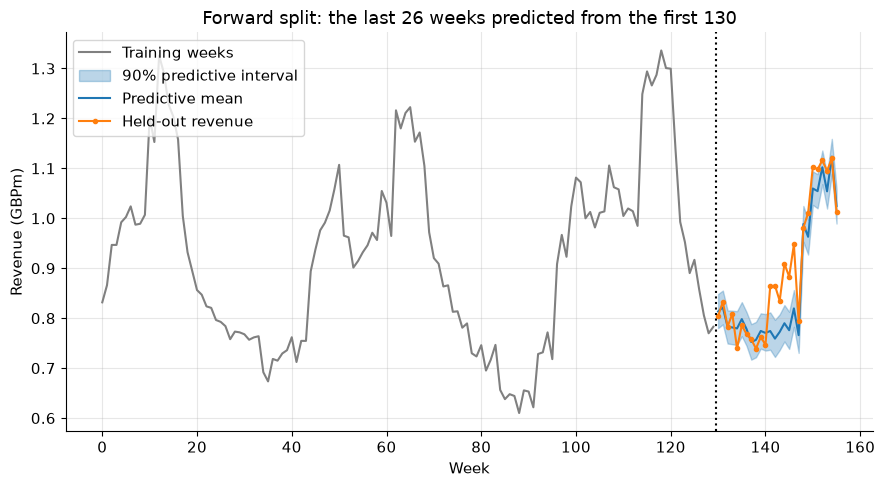

In [4]:
fig, ax = plt.subplots()
ax.plot(week[:n_train], y_all[:n_train], color="0.5", label="Training weeks")
ax.fill_between(week[n_train:], lo, hi, color="C0", alpha=0.3, label="90% predictive interval")
ax.plot(week[n_train:], pred.mean(axis=0), color="C0", label="Predictive mean")
ax.plot(week[n_train:], y_test, color="C1", marker="o", ms=3, label="Held-out revenue")
ax.axvline(n_train - 0.5, color="black", linestyle=":")
ax.set_xlabel("Week")
ax.set_ylabel("Revenue (GBPm)")
ax.set_title("Forward split: the last 26 weeks predicted from the first 130")
ax.legend()
fig.tight_layout()

The question to ask is Chapter 21's: do the 90 per cent intervals contain about 90 per cent of the held-out weeks?
Here they do not.
They contain 15 of the 26 weeks, 58 per cent, so the model is overconfident, the chapter's Model B, even though its typical miss of about 39,000 pounds a week looks respectable and the full-sample fit below looks well calibrated.
The misses are not scattered: six of the eleven are weeks 141 to 146, a product launch, and four more fall in the Black Friday and Christmas weeks that follow (149 to 153).
The launch effect was learned from two launches in the training weeks, and this one is about three times their size (the generator's `LAUNCHES`), so the model expects a small launch and the intervals, which describe only the noise around a model assumed correct, have no room for a bigger one.
A forward split is the check that finds this; nothing in the fitted model's own diagnostics could.
The remedy is a modelling decision, not a sampler setting: launch-specific effects where launch sizes are known in advance, or a likelihood with heavier tails or autocorrelated errors so the intervals carry more of the uncertainty that the baseline leaves.

## Part 2: posterior predictive checks on the full fit

The rest of the lab fits the model to every week and pushes posterior draws back through the likelihood.
`pm.sample_posterior_predictive` draws one simulated revenue series per retained posterior sample, using that sample's parameters and noise.

In [5]:
model = reference_model(nat)
with model:
    idata = pm.sample(**SAMPLE_KWARGS)
check(idata)

with model:
    pm.sample_posterior_predictive(
        idata, extend_inferencedata=True, random_seed=RANDOM_SEED, progressbar=False
    )

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [intercept, trend, season_a, season_b, omega_launch, delta_promo, gamma_log_price, gamma_distribution, gamma_stock, gamma_temperature, gamma_rainfall, gamma_category, beta_tv, beta_search, beta_meta, beta_youtube, beta_ooh, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 25 seconds.


Sampling: [y]


divergent transitions: 0, largest r_hat: 1.004


## Posterior predictive against observed, over time

Plotting the 90 per cent posterior predictive interval alongside the observed series is the most direct check: the observed line should mostly sit inside the shaded band, without long stretches where it hugs one edge or steps outside it.

share of observed weeks inside the 90% interval: 92%


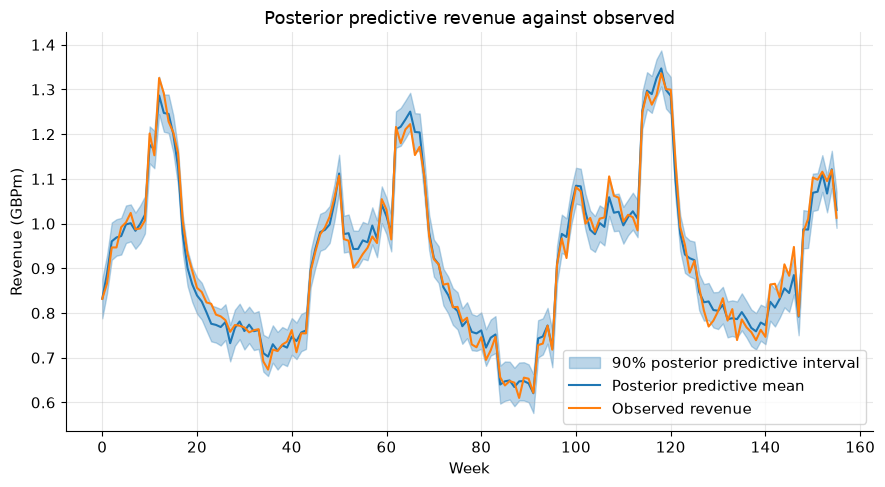

In [6]:
y_obs = idata.observed_data["y"].to_numpy()
pp = idata.posterior_predictive["y"].to_numpy().reshape(-1, y_obs.shape[0])
pp_lower, pp_upper = np.percentile(pp, [5, 95], axis=0)

fig, ax = plt.subplots()
ax.fill_between(
    week, pp_lower, pp_upper, color="C0", alpha=0.3, label="90% posterior predictive interval"
)
ax.plot(week, pp.mean(axis=0), color="C0", label="Posterior predictive mean")
ax.plot(week, y_obs, color="C1", linewidth=1.5, label="Observed revenue")
ax.set_xlabel("Week")
ax.set_ylabel("Revenue (GBPm)")
ax.set_title("Posterior predictive revenue against observed")
ax.legend()
fig.tight_layout()

within = ((y_obs >= pp_lower) & (y_obs <= pp_upper)).mean()
print(f"share of observed weeks inside the 90% interval: {within:.0%}")

## Posterior predictive against observed, as a density

The time series view checks the fit week by week; a density view checks whether the overall shape of weekly revenue, its centre and spread, is one the model would plausibly generate.

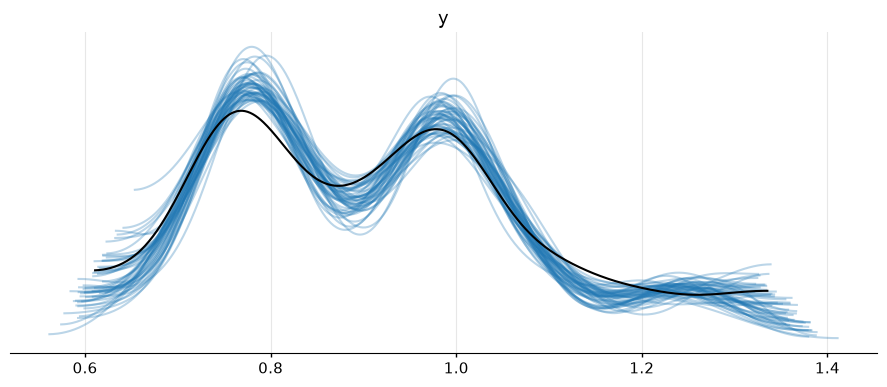

In [7]:
pc = az.plot_ppc_dist(idata, kind="kde", figure_kwargs={"figsize": (9, 4)})
pc.viz["figure"].item().tight_layout()

## Test quantities

A test quantity summarises a whole simulated dataset into one number, for example its mean or its maximum, so that the observed value can be located within the distribution of that number across posterior predictive draws.
The fraction of simulated datasets with a test quantity at least as extreme as the observed one is a Bayesian p-value: values near 0.5 say the observed statistic looks typical of what the model produces, while values near 0 or 1 flag a summary the model struggles to reproduce.

In [8]:
obs_mean, obs_max = y_obs.mean(), y_obs.max()
p_value_mean = float((pp.mean(axis=1) >= obs_mean).mean())
p_value_max = float((pp.max(axis=1) >= obs_max).mean())

print(f"observed mean revenue: {obs_mean:.3f}, Bayesian p-value: {p_value_mean:.3f}")
print(f"observed max revenue: {obs_max:.3f}, Bayesian p-value: {p_value_max:.3f}")

observed mean revenue: 0.922, Bayesian p-value: 0.507
observed max revenue: 1.336, Bayesian p-value: 0.813


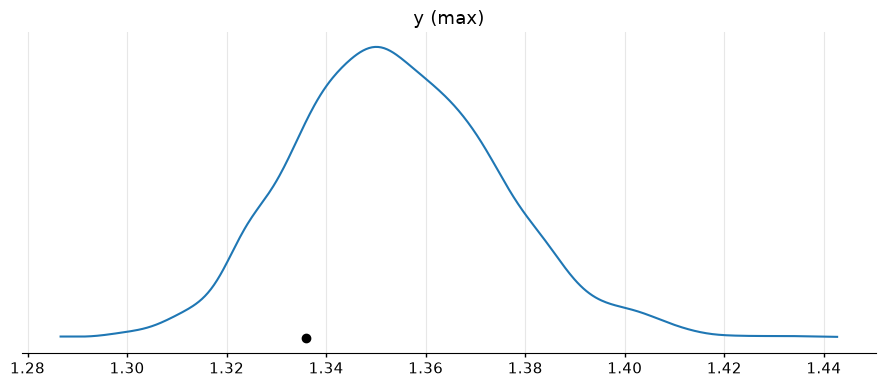

In [9]:
pc = az.plot_ppc_tstat(idata, t_stat="max", figure_kwargs={"figsize": (9, 4)})
pc.viz["figure"].item().tight_layout()

## Takeaway

The forward split is the test that matters for a model that will be used to plan the future, and this model fails it: its 90 per cent intervals contained only 15 of 26 held-out weeks, mostly because the held-out period includes a launch far bigger than any the model had seen.
The posterior predictive checks on the full fit ask a smaller question, whether the model can generate data that look like the data it was fitted to.
The mean is an easy test (p-value about 0.5), since the intercept is fitted to the average level directly.
The maximum is a harder one, because a linear model with a single noise level has no special mechanism for spikes; here its p-value is about 0.8, so the real series peaks a little lower than the model's simulated series usually do, but not by enough to be alarming.
In-sample, 92 per cent of weeks sit inside the 90 per cent band, which shows how much more forgiving a check on the fitted weeks is than one on weeks the model has not seen.
None of these checks says the media attribution is right: `r_hat` and ESS only confirm the sampler explored the model as written, and predictive checks only that the model reproduces observable features of the business.
They catch misspecification the convergence diagnostics cannot, such as missing seasonality, a variance that should grow with the level, or extreme weeks the likelihood was never built to produce.